# Morrell's size-specific energy against Bond on the ten surveys: the crusher equation step by step, two fitted variants held out and a negative work index read honestly

**Question:** Does Morrell's size-specific energy for a conventional crusher, set beside Bond's law on the same inputs, explain the motor power of the ten HP500 surveys when each survey is held out, and what does its fitted no-load term say about the ore?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebook 02 of this topic and notebook 02 of topic 05
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- write Morrell's equation for the specific energy of a conventional crusher, say what each of its terms is and where its units come out, and evaluate it on one survey beside Bond's energy for the same reduction;
- turn both laws into a design column, the power per unit of work index, and read what each column does against the measured power of the ten surveys;
- hold each survey out in turn and compare Bond, Morrell and the setting-only line on the same folds and the same error;
- recognise a fitted work index that has the wrong sign, say why a variant that predicts well with it is not the Morrell model, and name what the surveys cannot decide.

## Setup

Numpy and matplotlib. Everything else, the equations of both laws and the fits, comes from the repository's pipeline.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports bring the survey reader, the backbone builder, the HP500 modules (the setting-only line, the Morrell fit and the CrusherCal functions), Morrell's equations and the Bond oracle.

In [1]:

# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, blin, loo, morrell_fit
from pipeline.model.crusher import morrell
from pipeline.oracles import bond_energy_kwh_t, bond_power_kw
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv` and `VERSION`. Morrell's equations come from the GMSG guideline on the Morrell method, Annex B, section B.2.2 (https://www.smctesting.com/documents/Morrell_method_for_determining_comminution_circuit_specific_energy_and_assessing_energy_utilization_efficiency_of_existing_circuits.pdf), which is the source the pipeline's module cites; the primary paper is Morrell (2009), https://doi.org/10.1016/j.mineng.2009.01.005.

The cell reads the survey table and builds the backbone, whose P80 of each survey is the product size that both laws need, since the plant measured none.

In [2]:

# The ten surveys, and the backbone's P80 of each (a model output, used below as an input and never as
# a target)
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
bdoc = backbone.build(surveys, version)
rows = bdoc["surveys"]
css = np.array([r["measured"]["css_mm"] for r in rows])
f80 = np.array([r["measured"]["f80_mm"] for r in rows])
tph = np.array([r["measured"]["feed_tph"] for r in rows])
kw = np.array([r["measured"]["power_kw"] for r in rows])
p80 = np.array([r["backbone"]["p80_mm"] for r in rows])
print('surveys: {} | release label: {}'.format(len(surveys), version))
text = (
    'power measured: {:.0f} to {:.0f} kW | feed: {:.0f} to {:.0f} '
    't/h | backbone P80: {:.1f} to {:.1f} mm'
)
print(text.format(kw.min(), kw.max(), tph.min(), tph.max(), p80.min(), p80.max()))


surveys: 10 | release label: 0.12.001
power measured: 187 to 355 kW | feed: 813 to 1639 t/h | backbone P80: 21.2 to 36.6 mm


## Method

**Step 1, Morrell's equation for one survey.** Morrell's method prices a size reduction in a crusher, in the form given by the GMSG guideline (Annex B, section B.2.2, equations B4 and B5), as

$$W_c = S_c\,K_2\,M_{ic}\;4\left(x_2^{f(x_2)} - x_1^{f(x_1)}\right)\ [\mathrm{kWh/t}],\qquad f(x) = -\left(0.295 + \frac{x}{10^{6}}\right),\qquad S_c = \min\left(1,\ 55\,(x_1 x_2)^{-0.2}\right)$$

with $x_1$ and $x_2$ the 80 percent passing sizes of the feed and of the product in micrometres, $K_2$ equal to 1.0 for a crusher in closed circuit with a classifying screen (and 1.19 in open circuit; the pipeline's functions take the closed circuit by default and this notebook keeps it, which changes no result below because the fitted index absorbs any constant factor), and $M_{ic}$ the crusher work index of the ore in kWh/t, measured by the SMC Test. Bond's law ($W = 10\,W_i\,(P_{80}^{-1/2} - F_{80}^{-1/2})$) has the same shape of answer, an energy per tonne, from a different dependence on size. The size term is dimensionless, a micrometre size raised to a small negative power, so $W_c$ carries the unit of $M_{ic}$, and $W_c$ times the throughput in t/h is a power in kW. The cell evaluates every term on survey 1 with $M_{ic} = 1$ kWh/t, taking $x_1$ from the measured f80 and $x_2$ from the backbone's P80, and prints Bond's energy for the same reduction at $W_i = 1$ kWh/t so the two laws can be read per unit of their index.

In [3]:

# Equation B4 of the guideline on survey 1, one term at a time, with M_ic = 1 kWh/t
x1, x2 = f80[0] * 1000, p80[0] * 1000
size = morrell.size_term(x1, x2)
s_c = morrell.hardness_parameter(x1, x2)
w_c = morrell.crusher_specific_energy_kwh_t(x1, x2, 1.0)
w_bond = bond_energy_kwh_t(f80[0], p80[0], 1.0)
print((
    'f(x1) = {:.4f}, f(x2) = {:.4f} with x1 = {:.0f} um and x2 = '
    '{:.0f} um'
).format(morrell.f_exponent(x1), morrell.f_exponent(x2), x1, x2))
print('size term 4 (x2^f(x2) - x1^f(x1)) = {:.5f}'.format(size))
print('hardness parameter S_c = {:.4f}'.format(s_c))
print('W_c = S_c K2 M_ic size term = {:.5f} kWh/t (M_ic = 1)'.format(w_c))
print((
    'Bond energy of the same reduction at Wi = 1 kWh/t = {:.5f} '
    'kWh/t'
).format(w_bond))


f(x1) = -0.3830, f(x2) = -0.3276 with x1 = 88000 um and x2 = 32560 um
size term 4 (x2^f(x2) - x1^f(x1)) = 0.08192
hardness parameter S_c = 0.7062
W_c = S_c K2 M_ic size term = 0.05785 kWh/t (M_ic = 1)
Bond energy of the same reduction at Wi = 1 kWh/t = 0.02171 kWh/t


On survey 1 the feed has an f80 of 88 mm and the backbone's product a P80 of 32.56 mm, a reduction ratio of 2.7. The size term is 0.08192, the hardness parameter $S_c$ is 0.7062 (below 1, so the guideline's correction acts and the energy is scaled down by almost a third), and the energy per unit of work index is 0.05785 kWh/t, against 0.02171 kWh/t for Bond at the same $W_i$ of 1. Morrell's law therefore prices this reduction at 2.7 times Bond's for a unit index, which is not a disagreement: the two indices are different tests on different scales, and each ore carries its own value of each. What matters below is what each law does with the size and the throughput once its index is fitted. The next cell asks whether the guideline's clamp at 1 ever matters on these surveys.

In [4]:

# The hardness parameter of every survey, to see whether the guideline's clamp at 1 ever acts
s_all = [morrell.hardness_parameter(a * 1000, b * 1000) for a, b in zip(f80, p80)]
print('S_c over the ten surveys: {:.3f} to {:.3f}'.format(min(s_all), max(s_all)))


S_c over the ten surveys: 0.629 to 0.872


$S_c$ runs from 0.629 to 0.872 over the ten surveys: the correction acts on all of them and the clamp never does, so the rule `min(1, ...)` of the guideline is not what separates one survey from another. $S_c$ falls as the sizes grow, so it shaves the energy most for the coarsest reductions.

**Step 2, the design column.** The pipeline writes both laws as a power linear in one unknown. For a survey with measured f80, backbone P80 and measured feed rate $Q$, the power predicted by Morrell is $M_{ic}\,g$ with $g = W_c(M_{ic} = 1)\,Q$ in kW per kWh/t (`morrell_fit.design_column`), and the power predicted by Bond is $W_i\,g_B$ with $g_B = W(W_i = 1)\,Q$. Putting the measured throughput in the column is a choice of the model, the plant's feed rate being an input of the power question; the P80 is the backbone's and is an input too, never a target, because the plant measured none. The cell builds both columns for the ten surveys and prints them with the setting and the measured power.

In [5]:

# The design column of each survey: kW per kWh/t of work index, for Morrell and for Bond, at the
# measured t/h
g_morrell = morrell_fit.design_column(f80, p80, tph)
g_bond = np.array([bond_power_kw(q, a, b, 1.0) for q, a, b in zip(tph, f80, p80)])
print((
    'survey  CSS [mm]  f80 [mm]  P80 [mm]    t/h  kW measured  g '
    'Morrell  g Bond'
))
for k in range(len(kw)):
    print(f"{k + 1:6d} {css[k]:9.0f} {f80[k]:9.0f} {p80[k]:9.2f} {tph[k]:6.0f}", end=" ")
    print(f"{kw[k]:11.0f} {g_morrell[k]:10.1f} {g_bond[k]:7.1f}")


survey  CSS [mm]  f80 [mm]  P80 [mm]    t/h  kW measured  g Morrell  g Bond
     1        54        88     32.56   1639         209       94.8    35.6
     2        54        84     31.36   1267         212       74.5    27.8
     3        48        47     21.23   1240         262       76.0    27.9
     4        48        88     30.80   1034         349       64.1    24.1
     5        48        62     24.54   1124         325       72.4    26.6
     6        40        79     26.54    813         355       56.4    21.0
     7        38       140     36.60   1050         306       65.7    26.8
     8        44       123     35.69   1138         325       70.2    27.8
     9        40        81     26.97    820         350       56.7    21.1
    10        55        81     30.72   1334         187       78.6    29.2


The Morrell column runs from 56.4 to 94.8 kW per kWh/t and the Bond column from 21.0 to 35.6; the ratio of the two lies between 2.45 and 2.73, so over these surveys the two laws are close to proportional, within about 10 percent of one scale factor: whatever one does with the data, the other does with that factor and a mild tilt. Measured power spans 187 to 355 kW. Each unit of work index buys more power in the survey with the large throughput, so the question for both laws is whether the columns rank the surveys as the motor does. The cell counts that with the correlation, and adds the setting for reference.

In [6]:

# Correlation of each design column, and of the setting, with the measured power
r_morrell = np.corrcoef(g_morrell, kw)[0, 1]
r_bond = np.corrcoef(g_bond, kw)[0, 1]
r_css = np.corrcoef(css, kw)[0, 1]
print((
    'correlation with measured kW: Morrell column {:.2f}, Bond '
    'column {:.2f}, setting CSS {:.2f}'
).format(r_morrell, r_bond, r_css))


correlation with measured kW: Morrell column -0.81, Bond column -0.78, setting CSS -0.82


The figure plots the measured power against each column, one point per survey, numbered as in the table.

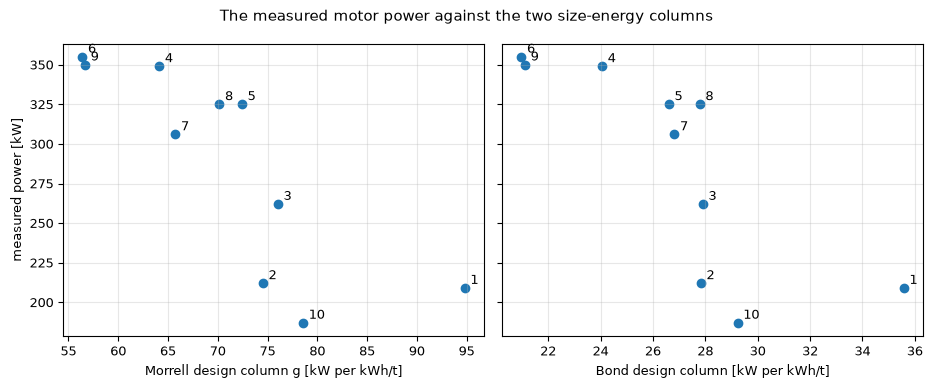

In [7]:

# Measured power against each design column, one point per survey
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
panels = (
    (g_morrell, 'Morrell design column g [kW per kWh/t]'),
    (g_bond, 'Bond design column [kW per kWh/t]'),
)
for ax, (column, xlabel) in zip(axes, panels):
    ax.scatter(column, kw, color="tab:blue")
    for k in range(len(kw)):
        ax.annotate(str(k + 1), (column[k], kw[k]), textcoords="offset points", xytext=(4, 3))
    ax.set_xlabel(xlabel)
axes[0].set_ylabel('measured power [kW]')
fig.suptitle('The measured motor power against the two size-energy columns')
fig.tight_layout()
plt.show()


Both columns correlate negatively with the measured power (-0.81 for Morrell, -0.78 for Bond), about as strongly as the setting itself (-0.82). Two things follow. A law whose prediction is proportional to its column, which is every model with a work index and no intercept, predicts the highest power where the column is highest, and the figure shows that is where the motor draws least: the surveys with the large throughput and the coarse setting. And the sign is not an accident of Morrell's constants, since Bond's column does the same; it comes from what the plant did: the surveys with the finer setting have the lower throughput and the higher measured power. The figure does not show that Morrell's equation is wrong for crushers in general; it shows that on this data the product of an energy per tonne and the measured throughput points the wrong way: the motor drew the least power where the feed rate was the highest.

## Comparison

Morrell's index is not published for the Minas Rio itabirite, so it has to be fitted, and so does Bond's (the engine ships a blend value, $W_i$ = 9 kWh/t, from the paper's bands). The comparison uses the product's own protocol, strict leave-one-survey-out: each model is refit on nine surveys, with `morrell_fit.fit_through_origin` for the index alone and `morrell_fit.fit_with_no_load` for the index plus a no-load power (the guideline defines the net power as the motor power less the no-load, so a measured motor power carries it), and predicts the tenth. Seven models run on the same folds. The first is the product's own power on this machine, the current-based form $P_c = 1.30\,P_d + 110$ kW of Rocha et al. (2024), with $P_d$ the Bond draw at the engine's own throughput, F80 and P80 and the blend index of 9 kWh/t: the backbone document built above holds it per survey as `calibrated_power_kw`, and since nothing in it is refit in the folds it is the same in every fold. Then Bond at the blend index on the measured throughput with no fit, which uses no slope and no no-load term and is therefore not the engine's power, Bond refit, Bond with a no-load term, Morrell refit, Morrell with a no-load term, and, as the bar, the setting-only line, a straight line of the power on the closed-side setting refit on the nine surveys of each fold (`blin.fit_line`). The error is the mean absolute percentage error of the held-out power.

Written out, the protocol for a law with design column $g$ (Morrell's or Bond's) and survey $i$ held out is

$$\bigl(\hat M_{-i}, \hat P_{0,-i}\bigr) = \arg\min_{M,\,P_0} \sum_{j \ne i} \bigl(P_j - M g_j - P_0\bigr)^2, \qquad \hat P_{-i} = \hat M_{-i}\, g_i + \hat P_{0,-i}, \qquad \mathrm{MAPE} = \frac{100}{n} \sum_{i=1}^{n} \frac{|P_i - \hat P_{-i}|}{P_i},$$

where $P_j$ is the measured motor power of survey $j$ in kW, $g_j$ its design column in kW per kWh/t, $M$ the work index of the law ($M_{ic}$ or $W_i$), $P_0$ the no-load power (fixed at zero for the through-origin variants), $\hat P_{-i}$ the prediction for the held-out survey from the nine others, and $n = 10$. The held-out survey never enters its own fit, which is what makes the error an estimate of how the law would do on an eleventh survey.

In [8]:

# Leave-one-survey-out: each model is refit on nine surveys and predicts the tenth
names = ("engine_power", "bond_nominal", "bond", "bond_noload", "morrell", "morrell_noload", "b_lin")
n = len(kw)
held = {name: np.zeros(n) for name in names}
fitted = []
for i in range(n):
    train = np.array([j for j in range(n) if j != i])
    held["engine_power"][i] = rows[i]["backbone"]["calibrated_power_kw"]   # Pc = 1.30 Pd + 110, no fit
    held["bond_nominal"][i] = 9.0 * g_bond[i]
    held["bond"][i] = morrell_fit.fit_through_origin(g_bond, kw, train) * g_bond[i]
    m_b, p_b = morrell_fit.fit_with_no_load(g_bond, kw, train)
    held["bond_noload"][i] = m_b * g_bond[i] + p_b
    held["morrell"][i] = morrell_fit.fit_through_origin(g_morrell, kw, train) * g_morrell[i]
    m_m, p_m = morrell_fit.fit_with_no_load(g_morrell, kw, train)
    held["morrell_noload"][i] = m_m * g_morrell[i] + p_m
    fitted.append((m_m, p_m))
    held["b_lin"][i] = blin.predict_line(blin.fit_line(css, kw, train), css[i])


The cell below prints the held-out error of the seven models, the mean absolute percentage error and the root mean square error in kW, so that the ranking can be read in one place.

In [9]:

# Held-out error of each model on the power
label = {
    "engine_power": "the engine's HP500 power, 1.30 Pd + 110",
    "bond_nominal": "Bond, Wi = 9 on the measured Q, no fit",
    "bond": 'Bond, Wi refit through the origin',
    "bond_noload": 'Bond, Wi and a no-load term',
    "morrell": 'Morrell, M_ic refit through the origin',
    "morrell_noload": 'Morrell, M_ic and a no-load term',
    "b_lin": 'the setting-only line',
}
print('model                                     MAPE [%]  RMSE [kW]')
for name in names:
    print(f"{label[name]:42s} {loo.mape(kw, held[name]):8.2f} {loo.rmse(kw, held[name]):10.2f}")
print("the engine's HP500 power: {:.1f} to {:.1f} kW, correlation with the measured power {:+.2f}".format(
    held["engine_power"].min(), held["engine_power"].max(), np.corrcoef(kw, held["engine_power"])[0, 1]))
print(f"the measured power: {kw.min():.0f} to {kw.max():.0f} kW")


model                                     MAPE [%]  RMSE [kW]
the engine's HP500 power, 1.30 Pd + 110       47.58     132.85
Bond, Wi = 9 on the measured Q, no fit        31.72     103.73
Bond, Wi refit through the origin             36.44     109.72
Bond, Wi and a no-load term                   16.27      47.28
Morrell, M_ic refit through the origin        38.08     111.67
Morrell, M_ic and a no-load term              15.21      46.53
the setting-only line                         12.78      44.56
the engine's HP500 power: 365.0 to 418.7 kW, correlation with the measured power -0.45
the measured power: 187 to 355 kW


The product's own HP500 power is the worst row of the table, 47.58 percent with an RMSE of 132.85 kW: it predicts 365.0 to 418.7 kW for every survey, so its lowest prediction is above the highest measured power, 355 kW, and it correlates -0.45 with the measured power, so it ranks the surveys the wrong way round as well. Held out, Bond at the blend index on the measured throughput gives 31.72 percent, Bond refit 36.44, Morrell refit 38.08, and the two variants with a no-load term 16.27 for Bond and 15.21 for Morrell, against 12.78 for the setting-only line. The through-origin Morrell is the worst of the lot, and no better than Bond refit in the same form (36.44): on these surveys the published size-specific energy does not beat the older law, it only restates it. Adding a no-load term turns 38.08 into 15.21, which is a large gain, and brings Morrell to within 2.44 points of a line that uses nothing but the setting. Bond with the same extra term reaches 16.27, only 1.05 points behind, so the gain comes from the intercept and not from Morrell's size law. The next cell checks that these numbers are the pipeline's own.

In [10]:

# One reproduction check: the pipeline's own held-out document, built live, must give the same MAPE
strict = loo.build(bdoc, version)["loo"]["kW"]["strict"]
ours = (loo.mape(kw, held["morrell"]), loo.mape(kw, held["morrell_noload"]), loo.mape(kw, held["b_lin"]))
theirs = (strict["Morrell"]["mape_pct"], strict["Morrell_noload"]["mape_pct"], strict["B_lin"]["mape_pct"])
for tag, a, b in zip(("Morrell refit", "Morrell with a no-load term", "the setting-only line"), ours, theirs):
    print('{:32s} here {:6.2f} %, pipeline {:6.2f} %'.format(tag, a, b))
print('all three agree: {}'.format(np.allclose(ours, theirs, atol=0.005)))


Morrell refit                    here  38.08 %, pipeline  38.08 %
Morrell with a no-load term      here  15.21 %, pipeline  15.21 %
the setting-only line            here  12.78 %, pipeline  12.78 %
all three agree: True


The three values agree to the second decimal, so the fold loop of this notebook is the loop of the product's validation document; the other four models (the engine's own power, Bond at the blend index, Bond refit and Bond with a no-load term) have no counterpart in that document and are what this notebook adds. The figure draws the measured power against the held-out prediction of five models: the engine's own power, Bond refit, Morrell and Morrell with a no-load term, and the setting-only line, with the identity line.

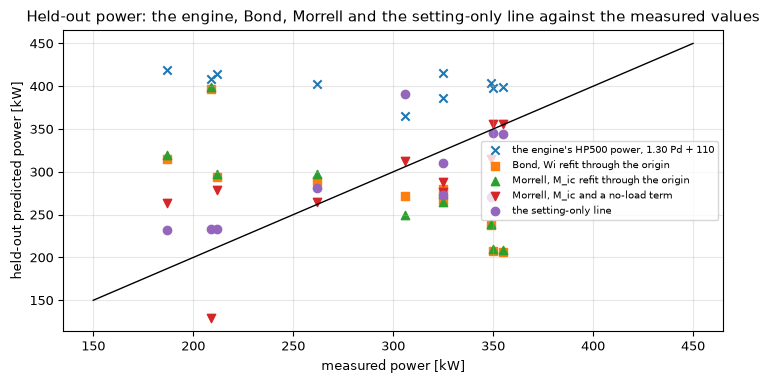

In [11]:

# Measured power against the held-out prediction of five models
fig, ax = plt.subplots()
for name, marker in (("engine_power", "x"), ("bond", "s"), ("morrell", "^"), ("morrell_noload", "v"), ("b_lin", "o")):
    ax.scatter(kw, held[name], marker=marker, label=label[name])
ax.plot([150, 450], [150, 450], color="black", lw=1)
ax.set_xlabel('measured power [kW]')
ax.set_ylabel('held-out predicted power [kW]')
ax.set_title((
    'Held-out power: the engine, Bond, Morrell and the setting-only line against '
    'the measured values'
))
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()


Points on the identity line are perfect predictions. The engine's own power, the crosses, is a flat band between 365 and 419 kW whatever the plant drew: its no-load term of 110 kW and its slope of 1.30 lift a Bond draw that barely changes between surveys to above every measurement. The through-origin models, Bond refit and Morrell, sit in a cloud that falls as the measured power rises, far above the line at the low measured powers and below it at the high ones, the shape of a model whose slope has the wrong sign being forced through the origin; their held-out RMSE is 109.7 and 111.7 kW on a measured spread of 187 to 355 kW. Morrell with a no-load term and the setting-only line lie closer to the line, with a scatter of 46.5 and 44.6 kW. The figure does not say why the no-load variant works; the band below and then the coefficients do.

The scatter can be put in one number the way CrusherCal does for its own model: the 80 percent predictive band of a held-out model is its prediction plus or minus 1.2816 times the standard deviation of its held-out residuals (`loo.predictive_band`). The cell prints that band for the four models that the figure shows.

In [12]:

# The 80 percent predictive band that each model's held-out residuals would earn, with CrusherCal's
# own function
print((
    'model                                     sigma [kW]  '
    'half-width [kW]'
))
for name in ("bond", "morrell", "morrell_noload", "b_lin"):
    band = loo.predictive_band(kw - held[name])
    print(f"{label[name]:42s} {band['sigma']:9.1f} {band['halfwidth']:20.1f}")


model                                     sigma [kW]  half-width [kW]
Bond, Wi refit through the origin              115.0                147.4
Morrell, M_ic refit through the origin         117.0                150.0
Morrell, M_ic and a no-load term                48.9                 62.7
the setting-only line                           46.8                 60.0


The 80 percent band of Bond refit is plus or minus 147 kW and that of Morrell plus or minus 150 kW, wider than the whole measured range of 168 kW (from 187 to 355): a band that wide says nothing about which survey draws more. Morrell with a no-load term gives plus or minus 63 kW and the setting-only line plus or minus 60 kW, about a third of that range on each side. The band is the cost of the prediction in kW, and it reproduces the ordering of the MAPE: the through-origin laws carry no information about the power of a held-out survey, and the no-load line does only because its column carries the measured throughput, as the cells below show.

**The negative work index.** A work index is a measured property of a rock, a positive energy. The variant with a no-load term fits two numbers per fold, and the cell prints them: the index $M_{ic}$ the fold chose, the no-load power, and whether the index is positive. The pipeline flags the same thing in its document as `noload_variant_m_ic_positive`.

In [13]:

# The coefficients each fold fitted for Morrell with a no-load term
print('held-out survey   M_ic [kWh/t]   no-load [kW]   M_ic positive')
for k, (m_ic, no_load) in enumerate(fitted):
    print(f"{k + 1:16d} {m_ic:14.2f} {no_load:14.1f} {m_ic > 0!s:>14}")
print('smallest measured power in the ten surveys: {:.0f} kW'.format(kw.min()))


held-out survey   M_ic [kWh/t]   no-load [kW]   M_ic positive
               1          -6.29          726.7          False
               2          -4.46          611.0          False
               3          -4.65          618.4          False
               4          -4.46          601.4          False
               5          -4.73          618.5          False
               6          -4.68          620.2          False
               7          -4.70          622.0          False
               8          -4.64          613.5          False
               9          -4.74          625.2          False
              10          -4.16          590.7          False
smallest measured power in the ten surveys: 187 kW


The index is negative in all ten folds, from -6.3 to -4.2 kWh/t, and the fitted no-load power is 591 to 727 kW, which is 3.2 to 3.9 times the smallest power the motor ever drew, 187 kW, in a crusher whose idle draw cannot exceed what it draws loaded. Neither number is physical. A negative $M_{ic}$ means that the energy the law assigns to the survey is subtracted: the fit has found that power falls as the Morrell column rises (the correlation of the figure above) and has solved for a negative slope and an intercept large enough to bring the line back to the data. The prediction is then a straight line with a negative slope in a column that rises with both the throughput and the setting, so it can be a good predictor without the equation being used as an energy law at all. The cell measures what the column and the prediction follow, and scores the setting-only line's own held-out fit with the throughput in place of the setting.

In [14]:

# What the no-load variant follows: the design column and the held-out prediction against the throughput,
# the setting and the setting-only line
pairs = (
    ('correlation of the Morrell column g with the throughput', g_morrell, tph),
    ('correlation of the Morrell column g with the setting CSS', g_morrell, css),
    ('correlation of the throughput with the setting CSS', tph, css),
    ('correlation of the throughput with the measured kW', tph, kw),
    ('correlation of the no-load prediction with the throughput', held["morrell_noload"], tph),
    ('correlation of the no-load prediction with the setting CSS', held["morrell_noload"], css),
    ("correlation, no-load prediction and setting-only line", held["morrell_noload"], held["b_lin"]),
)
for tag, first, second in pairs:
    print(f"{tag:62s} {np.corrcoef(first, second)[0, 1]:+.2f}")
# The setting-only line's own held-out fit, made on the throughput in place of the setting
held_tph = np.zeros(n)
for i in range(n):
    train = np.delete(np.arange(n), i)
    held_tph[i] = blin.predict_line(blin.fit_line(tph, kw, train), tph[i])
print(f"held-out line of the power on the throughput: MAPE {loo.mape(kw, held_tph):.2f} %, "
      f"RMSE {loo.rmse(kw, held_tph):.2f} kW")


correlation of the Morrell column g with the throughput        +0.99
correlation of the Morrell column g with the setting CSS       +0.79
correlation of the throughput with the setting CSS             +0.81
correlation of the throughput with the measured kW             -0.85
correlation of the no-load prediction with the throughput      -0.96
correlation of the no-load prediction with the setting CSS     -0.71
correlation, no-load prediction and setting-only line          +0.66
held-out line of the power on the throughput: MAPE 14.37 %, RMSE 42.41 kW


The design column is the throughput in all but name: it correlates +0.99 with the measured t/h and +0.79 with the setting, and over these ten surveys the throughput and the setting themselves move together (+0.81). The held-out values of the no-load variant follow the throughput (-0.96) more closely than the setting (-0.71) or the setting-only line (+0.66). A plain held-out line of the power on the throughput, the least-squares fit of the setting-only line with the t/h column in place of the setting, scores 14.37 percent and 42.41 kW, better than Morrell with a no-load term (15.21 percent and 46.53 kW): the variant is a line on the measured feed rate, and Morrell's energy law adds only the small tilt between its column and the throughput, which costs it accuracy. Which of the two the motor follows, these surveys cannot say: the throughput correlates -0.85 with the measured power and the setting -0.82, and the two are tied to each other. It is a descriptive line and the product reports it as one. The figure draws the two lines fitted on all ten surveys in the plane of the column, to see what the fit does.

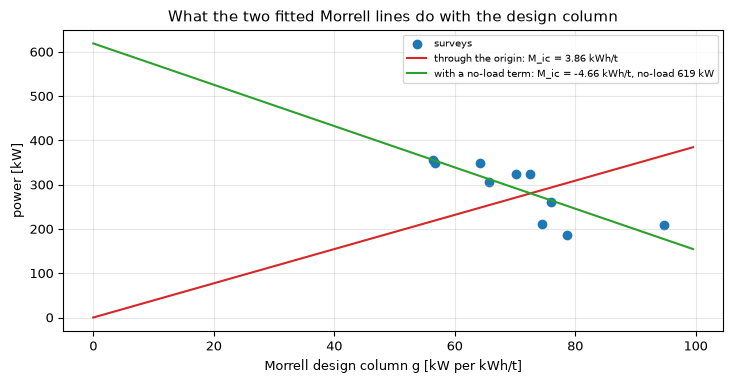

In [15]:

# The two Morrell lines fitted on all ten surveys, in the plane of the design column
every = np.arange(n)
m_all = morrell_fit.fit_through_origin(g_morrell, kw, every)
m_nl, p_nl = morrell_fit.fit_with_no_load(g_morrell, kw, every)
x = np.linspace(0, g_morrell.max() * 1.05, 50)
fig, ax = plt.subplots()
ax.scatter(g_morrell, kw, color="tab:blue", label='surveys')
label_o = 'through the origin: M_ic = {:.2f} kWh/t'.format(m_all)
label_n = 'with a no-load term: M_ic = {:.2f} kWh/t, no-load {:.0f} kW'.format(m_nl, p_nl)
ax.plot(x, m_all * x, color="tab:red", label=label_o)
ax.plot(x, m_nl * x + p_nl, color="tab:green", label=label_n)
ax.set_xlabel('Morrell design column g [kW per kWh/t]')
ax.set_ylabel('power [kW]')
ax.set_title('What the two fitted Morrell lines do with the design column')
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()


Fitted on all ten surveys, the through-origin line has an index of 3.86 kWh/t and runs up through the middle of a cloud that goes down; the line with a no-load term has an index of -4.66 kWh/t and a no-load power of 619 kW, falls across the cloud and is the better description of the points. The figure shows why the positive-index model fails and the negative-index model does not: the data want a downward slope and the equation, with a work index that is a positive energy, can only give an upward one. It does not show that a different feed definition, or Morrell's index measured by the SMC Test on the real ore, would not give a positive fit; the ten surveys contain no such measurement.

### Sensitivity of the comparison: the borrowed product size and the circuit factor

Two inputs of the comparison are not measurements. The product P80 of every survey is the backbone's, because the plant measured none, and the circuit factor $K_2$ is set to the closed-circuit 1.0 although the HP500 circuit could be read as open (1.19). If either choice carried the verdict, the verdict would be about the choice. The cell scales every backbone P80 by a common factor from 0.7 to 1.3, rebuilds both design columns, reruns the strict leave-one-survey-out fit of the four fitted laws and records each held-out MAPE; then it repeats the comparison at the true P80 with the open-circuit factor. The setting-only line reads only the setting, so it is the flat reference.

In [16]:
# Held-out MAPE of the four fitted laws with every backbone P80 scaled, and with the open-circuit factor K2 = 1.19
def held_out_mape(column, with_no_load):
    pred = np.zeros(n)
    for i in range(n):
        train = np.array([j for j in range(n) if j != i])
        if with_no_load:
            m_i, p_i = morrell_fit.fit_with_no_load(column, kw, train)
            pred[i] = m_i * column[i] + p_i
        else:
            pred[i] = morrell_fit.fit_through_origin(column, kw, train) * column[i]
    return loo.mape(kw, pred)
scales = np.linspace(0.7, 1.3, 7)
curves = {"morrell": [], "morrell_noload": [], "bond": [], "bond_noload": []}
for s in scales:
    gm = morrell_fit.design_column(f80, p80 * s, tph)
    gb = np.array([bond_power_kw(q, a, b * s, 1.0) for q, a, b in zip(tph, f80, p80)])
    variants = (("morrell", gm, False), ("morrell_noload", gm, True), ("bond", gb, False), ("bond_noload", gb, True))
    for key, column, nl in variants:
        curves[key].append(held_out_mape(column, nl))
open_col = morrell_fit.design_column(f80, p80, tph, closed_circuit=False)
print("open circuit, Morrell through the origin and with no-load [%]:",
      round(held_out_mape(open_col, False), 2), round(held_out_mape(open_col, True), 2))
for key, values in curves.items():
    print(f"{label[key]:42s} MAPE over the P80 scales: {min(values):6.2f} to {max(values):6.2f} %")

open circuit, Morrell through the origin and with no-load [%]: 38.08 15.21
Morrell, M_ic refit through the origin     MAPE over the P80 scales:  35.22 to  40.09 %
Morrell, M_ic and a no-load term           MAPE over the P80 scales:  14.71 to  18.13 %
Bond, Wi refit through the origin          MAPE over the P80 scales:  33.34 to  38.81 %
Bond, Wi and a no-load term                MAPE over the P80 scales:  14.66 to  18.10 %


The figure draws the four curves against the common factor, with the held-out error of the setting-only line as a dashed horizontal line, so that each law can be read against the bar it has to beat at every scale of the borrowed product size.

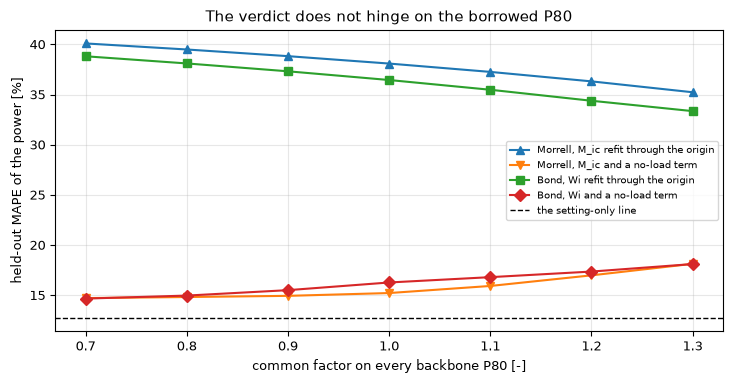

In [17]:
# Plot the held-out MAPE of each fitted law against the common P80 factor, with the setting-only line as the flat
# reference
fig, ax = plt.subplots()
for key, marker in (("morrell", "^"), ("morrell_noload", "v"), ("bond", "s"), ("bond_noload", "D")):
    ax.plot(scales, curves[key], marker + "-", label=label[key])
ax.axhline(loo.mape(kw, held["b_lin"]), color="black", lw=1, ls="--", label=label["b_lin"])
ax.set_xlabel("common factor on every backbone P80 [-]")
ax.set_ylabel("held-out MAPE of the power [%]")
ax.set_title("The verdict does not hinge on the borrowed P80")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

The verdict survives both borrowed inputs. Across a 30 percent error in every P80, up or down, the through-origin laws stay far behind the setting-only line and the no-load variants stay near it without passing it; the ranges printed by the cell above the figure give the extremes. Scaling the P80 moves the curves because it moves the size term unevenly between surveys, not because it fixes the sign of the column: the throughput still multiplies every column, and the throughput still runs against the measured power. The open circuit leaves both Morrell errors exactly where they were at the true P80, 38.08 and 15.21 percent, because $K_2$ multiplies every survey's column by the same 1.19 and the fitted index absorbs it. What the sweep cannot vary is the product size survey by survey; a measured P80 on each survey is the one input that could still change the picture, and the paper reports none.

### Using it on your own data: Morrell's power for your own crusher and index

The functions take any record, so a reader with an SMC Test of their own ore can price a crusher reduction with them directly: `crusher_specific_energy_kwh_t` for the energy per tonne and `crusher_power_kw` for the motor power, both with the sizes in micrometres, the index in kWh/t, the throughput in t/h, an optional no-load draw in kW and the circuit as a flag. What to check in the output: $S_c$ below one (the guideline's correction acts) or clamped at one, the size term positive (a product finer than the feed), and the power beside the measured motor power of the same period, never beside a model's. The record below is typed in to show the call and is not a property of any ore: a cone at 600 t/h from F80 120 mm to P80 28 mm, an index of 8 kWh/t and a no-load draw of 60 kW. The cell prints the energy and the power in both circuits and Bond's power of the same reduction at the engine's blend index of 9 kWh/t.

In [18]:
# Morrell's energy and motor power for a typed-in record (replace it with your own), in both circuits, beside Bond
own = {"f80_mm": 120.0, "p80_mm": 28.0, "tph": 600.0, "m_ic": 8.0, "no_load_kw": 60.0}
x1_own, x2_own = own["f80_mm"] * 1000, own["p80_mm"] * 1000
print("S_c =", round(morrell.hardness_parameter(x1_own, x2_own), 4), "| size term =",
      round(morrell.size_term(x1_own, x2_own), 5))
for closed in (True, False):
    w_own = morrell.crusher_specific_energy_kwh_t(x1_own, x2_own, own["m_ic"], closed_circuit=closed)
    kw_own = morrell.crusher_power_kw(x1_own, x2_own, own["m_ic"], own["tph"], own["no_load_kw"], closed_circuit=closed)
    circuit = "closed" if closed else "open"
    print(f"{circuit:6s} circuit: W_c = {w_own:.4f} kWh/t | motor power = {kw_own:.1f} kW")
bond_own = bond_power_kw(own["tph"], own["f80_mm"], own["p80_mm"], 9.0)
print(f"Bond power of the same reduction at Wi = 9 kWh/t: {bond_own:.1f} kW (no no-load term)")

S_c = 0.6841 | size term = 0.11523
closed circuit: W_c = 0.6306 kWh/t | motor power = 438.3 kW
open   circuit: W_c = 0.7504 kWh/t | motor power = 510.2 kW
Bond power of the same reduction at Wi = 9 kWh/t: 166.8 kW (no no-load term)


For the typed-in record $S_c$ is below one, so the hardness correction acts as it did on all ten surveys, and the size term is positive. The open circuit raises the energy by exactly the factor 1.19 over the closed one, which is why the factor could not change any fitted result above: a fitted index absorbs any constant. The power is the energy times the tonnes plus the no-load draw, and Bond's power of the same reduction at the engine's index comes out lower, the two laws being different tests on different scales. The comparison above is the warning that goes with these numbers: on the HP500 surveys neither law ranked the measured powers correctly once its index was fitted, so a reader who prices a crusher with Morrell's equation should hold it against the motor's own records before using it to size anything.

## Results

**Answer:** no. With each survey held out, Morrell's size-specific energy does not explain the motor power of the ten HP500 surveys better than Bond's law. Refit through the origin, the index alone on a motor power that still includes the no-load draw, Morrell has a held-out error of 38.08 percent, against 36.44 for Bond refit in the same form, 31.72 for Bond at the blend index on the measured throughput and 12.78 for the setting-only line; the product's own HP500 power, $1.30\,P_d + 110$ kW at the engine's throughput, is the worst of all, 47.58 percent, with a correlation of -0.45 with the measured power. Both laws fail for one reason the notebook measured: their design columns correlate -0.81 (Morrell) and -0.78 (Bond) with the measured power, and a model proportional to its column predicts the most power where the motor draws the least. The variant with a no-load term reaches 15.21 percent only by fitting a negative work index in all ten folds, from -6.3 to -4.2 kWh/t, and a no-load power of 591 to 727 kW, 3.2 to 3.9 times the smallest measured draw of 187 kW. Its column correlates +0.99 with the throughput, its held-out values -0.96, and a plain held-out line on the throughput does better, 14.37 percent: it is a descriptive line on the measured feed rate, not Morrell's model. Its fitted no-load term says nothing about the ore: it is the intercept of that line, not an idle draw of the crusher, and the work index it comes with is negative. What the ten surveys cannot decide is whether the throughput or the setting governs the motor, since the two move together (+0.81), and whether Morrell's equation, with an index measured by the SMC Test on this ore and a measured product size, would do better: no index was measured and the product size used is the backbone's.

## Summary

Morrell's crusher equation is a size-reduction energy priced per tonne, with a hardness correction and a work index that the ore must supply. Run on the HP500 surveys with the index fitted, it behaves like Bond's law rescaled and inherits its failure on this machine: the motor drew the least power where the feed rate was the highest, and a law that multiplies an energy per tonne by the throughput predicts the opposite direction. The only variant that predicts well does so with a negative work index and an impossible no-load power, which makes it a line on the measured throughput, and the product reports it that way; whether the throughput or the setting governs the motor, these surveys, in which the two move together, cannot say. The product's own current-based power does worse than either law, because its constant no-load term and slope sit above the measured draws; CrusherBayes, the Bayesian calibration that puts a discrepancy around the engine, is compared with that line in topic 08.

The verdict holds when every borrowed P80 moves by 30 percent and when the circuit factor changes, and the same functions price a reader's own record once an SMC index is at hand.

## References

- Morrell, S. (2009), Predicting the overall specific energy requirement of crushing, high pressure grinding roll and tumbling mill circuits, Minerals Engineering 22(6), 544-549. https://doi.org/10.1016/j.mineng.2009.01.005
- GMSG, Morrell Method for Determining Comminution Circuit Specific Energy and Assessing Energy Utilization Efficiency of Existing Circuits, Annex B, section B.2.2 (equations B4 and B5). https://www.smctesting.com/documents/Morrell_method_for_determining_comminution_circuit_specific_energy_and_assessing_energy_utilization_efficiency_of_existing_circuits.pdf
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193. https://onemine.org/documents/the-third-theory-of-comminution
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919